<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 007 Klasifikasi Bentuk Tim</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Sejauh ini bukti tim hanya datang dari bola: tim pemain terdekat atau skor kendali. Padahal bola hilang pada sekitar 41% frame dinilai, dan di sana keadaan hanya bertahan, sehingga pergantian possession yang terjadi saat bola hilang tidak terdeteksi atau salah waktu (pada GT publik hanya 2 dari 20 transisi cocok). Eksperimen ini menambahkan **sumber bukti kedua yang tidak memakai bola**: bentuk dan gerak tim.

Model dilatih dengan **pseudo-label algoritmik**: pada frame saat bola terlihat dan kendalinya jelas (|c| > 0,6 pada skor kendali lunak), tim yang menguasai bola diketahui. Dari fitur tingkat tim (kedalaman, lebar, kekompakan, kecepatan, posisi relatif kedua tim, dinormalkan terhadap arah serang), model belajar memprediksi tim itu. Model lalu diterapkan pada **semua** frame, terutama frame tanpa bola, dan hasilnya menjadi bukti tambahan bagi decoder Viterbi. λ dikalibrasi ulang ke acuan eksternal 006 agar perbandingan adil.

Tidak ada label tangan dan ground truth tidak dipakai. Validasi dilakukan antar babak terhadap pseudo-label, sehingga ia mengukur apakah bentuk tim memang membawa informasi kepemilikan, bukan akurasi terhadap ground truth.


# Metodologi

**ATD → arah serang per tim dan babak → fitur bentuk tim (tidak memakai bola) → pseudo-label dari bola (kendali jelas) → klasifikasi gradient boosting, validasi silang antar babak → peluang tim per frame → bukti tambahan bagi Viterbi → λ dikalibrasi ke acuan eksternal 006 → gap bola mati dari 004 → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

| asumsi | nilai | alasan |
|---|---|---|
| pseudo-label | skor kendali lunak σ = 3 m, \|c\| > 0,6, bola terlihat | kendali jelas; tim penguasa hampir pasti |
| arah serang | sisi tempat kepadatan posisi tim memuncak (kiper) = gawang sendiri | langsung dari data, per tim dan babak |
| fitur | rata-rata bergerak 2 detik (50 frame) | meredam derau per frame |
| bobot bukti bentuk κ | 0,02 (dan 0,05 sebagai sensitivitas) | 1/50: fitur dihaluskan 50 frame, jadi satu sampel independen ≈ 50 frame |
| target kalibrasi | sekitar 208 ± 21 possession, dari 006 | statistik pertandingan lain |

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin. Acuan eksternal diambil dari cache yang dibuat 006.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25; LEN, WID = 105.3, 68.0
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool); HALF = np.ones(N, int)
for h, a, b in BLOCKS3: GRADED[a:b + 1] = True; HALF[a:b + 1] = h
GRADED_MIN = GRADED.sum() / FPS / 60
OUT = Path(common.HERE) / "007_team_shape" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print(f"frames: {N} | dinilai: {GRADED.sum()} ({GRADED_MIN:.1f} menit)")

frames: 199319 | dinilai: 158857 (105.9 menit)


# Approach: Bentuk Tim sebagai Bukti Tanpa Bola

## [1] Arah serang

Kiper tim berada di dekat gawangnya sendiri, sehingga puncak kepadatan posisi tim sepanjang babak menunjukkan sisi yang dibela. Arah serang adalah sebaliknya. Ini diperlukan agar fitur "kedalaman" bermakna untuk kedua babak.

In [2]:
P, B, T = common.load_atd_arrays()
X, Y, SP = P[..., 0] * LEN, P[..., 1] * WID, P[..., 2]
PRES = np.isfinite(X)

ATTACK = {}                                    # (tim, babak) -> +1 menyerang ke kanan, -1 ke kiri
for half, a, b in BLOCKS3:
    for t in (0, 1):
        xs = X[a:b + 1][(T == t)[None] & PRES[a:b + 1]]
        hist, edges = np.histogram(xs, bins=np.linspace(0, LEN, 43))
        peak = 0.5 * (edges[hist.argmax()] + edges[hist.argmax() + 1])
        ATTACK[(t, half)] = 1 if peak < LEN / 2 else -1
print({("H" if t == 0 else "A", h): ("kanan" if d == 1 else "kiri") for (t, h), d in ATTACK.items()})

{('H', 1): 'kanan', ('A', 1): 'kiri', ('H', 2): 'kiri', ('A', 2): 'kanan'}


Dua tim harus menyerang ke arah berlawanan dalam satu babak, dan arah itu harus tertukar di babak kedua. Itu pemeriksaan kewajaran sederhana atas pembacaan kiper.

## [2] Fitur bentuk tim

Untuk tiap frame dan tiap tim (minimal lima pemain terlacak): kedalaman (rata-rata x), panjang (simpangan baku x), lebar (simpangan baku y), kekompakan (rata-rata jarak ke pusat tim), dan kecepatan rata-rata. Fitur dibangun dari sudut pandang tim *a* dengan koordinat dinormalkan sehingga *a* selalu menyerang ke +x; kedua tim digunakan bergantian sebagai *a* (augmentasi simetris), sehingga model tidak punya preferensi tim.

In [3]:
def team_stats(t):
    m = PRES & (T == t)[None]
    n = m.sum(1)
    with np.errstate(all="ignore"):
        xm = np.where(m, X, np.nan); ym = np.where(m, Y, np.nan); sm_ = np.where(m & np.isfinite(SP), SP, np.nan)
        mx, my = np.nanmean(xm, 1), np.nanmean(ym, 1)
        out = {"mx": mx, "my": my, "sx": np.nanstd(xm, 1), "sy": np.nanstd(ym, 1),
               "cmp": np.nanmean(np.hypot(xm - mx[:, None], ym - my[:, None]), 1), "spd": np.nanmean(sm_, 1)}
    for k in out: out[k][n < 5] = np.nan
    return out

def roll(a, w=50):
    return pd.Series(a).rolling(w, center=True, min_periods=w // 5).mean().values

def build_feats():
    S = [{k: roll(v) for k, v in team_stats(t).items()} for t in (0, 1)]
    cols = []
    for a_, b_ in ((0, 1), (1, 0)):                 # sudut pandang tim a; label: a menguasai bola
        dir_a = np.array([ATTACK[(a_, h)] for h in HALF])            # arah serang a per frame
        fr = lambda x: np.where(dir_a == 1, x, LEN - x)            # ke bingkai di mana a menyerang ke +x
        f = np.stack([fr(S[a_]["mx"]), fr(S[b_]["mx"]), S[a_]["sx"], S[b_]["sx"], S[a_]["sy"], S[b_]["sy"],
                      S[a_]["cmp"], S[b_]["cmp"], S[a_]["spd"], S[b_]["spd"],
                      fr(S[a_]["mx"]) - fr(S[b_]["mx"]), S[a_]["sx"] - S[b_]["sx"], S[a_]["cmp"] - S[b_]["cmp"], S[a_]["spd"] - S[b_]["spd"]], 1)
        cols.append(f)
    return np.stack(cols)                              # (2 sudut pandang, N, F)
FEATS = ["kedalaman a", "kedalaman b", "panjang a", "panjang b", "lebar a", "lebar b", "kompak a", "kompak b",
         "kecepatan a", "kecepatan b", "Δ kedalaman", "Δ panjang", "Δ kompak", "Δ kecepatan"]
F = common.cached("team_shape_feats", build_feats)
print("fitur:", F.shape, "| frame dinilai dengan fitur lengkap:", f"{np.mean(np.isfinite(F[0][GRADED]).all(1)):.1%}")

fitur: (2, 199319, 14) | frame dinilai dengan fitur lengkap: 95.4%


## [3] Pseudo-label dari bola

Frame dengan bola terlihat dan skor kendali lunak $|c| > 0{,}6$ diberi label tim penguasa. Frame tanpa bola tidak pernah menjadi contoh latih, sehingga model belajar dari frame yang jelas lalu diterapkan pada frame yang bukti bolanya kosong.

In [4]:
C_S3, OBS_S3 = common.soft_control(3.0)
conf = GRADED & OBS_S3 & (np.abs(C_S3) > 0.6)
y_h = (C_S3 > 0).astype(int)                           # 1 = H menguasai bola
rng = np.random.default_rng(0)
idx = np.flatnonzero(conf)
idx = idx[rng.random(len(idx)) < 0.1]                  # sub-sampel 10% (frame berurutan sangat berkorelasi)
print(f"frame kendali jelas: {conf.sum()} ({conf.sum() / GRADED.sum():.1%} dari dinilai) | sampel latih: {len(idx)} | H: {y_h[idx].mean():.1%}")

def XY(ix):
    Xa = np.concatenate([F[0][ix], F[1][ix]]); ya = np.concatenate([y_h[ix], 1 - y_h[ix]])
    return Xa, ya

def make_model():
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=0)

cv = []
for tr_h, te_h in ((1, 2), (2, 1)):
    tr, te = idx[HALF[idx] == tr_h], idx[HALF[idx] == te_h]
    Xtr, ytr = XY(tr)
    m = make_model().fit(Xtr, ytr)
    pH = 0.5 * (m.predict_proba(F[0][te])[:, 1] + 1 - m.predict_proba(F[1][te])[:, 1])
    cv.append({"latih": f"babak {tr_h}", "uji": f"babak {te_h}", "AUC": roc_auc_score(y_h[te], pH), "akurasi": accuracy_score(y_h[te], pH > 0.5), "n uji": len(te)})
display(pd.DataFrame(cv).round(3))

frame kendali jelas: 32193 (20.3% dari dinilai) | sampel latih: 3282 | H: 60.6%


,latih,uji,AUC,akurasi,n uji
0,babak 1,babak 2,0.806,0.737,1564
1,babak 2,babak 1,0.870,0.817,1718


AUC antar babak menunjukkan apakah bentuk tim membawa informasi kepemilikan yang berlaku di luar babak tempat ia dilatih. Angka ini diukur terhadap pseudo-label dari bola, bukan ground truth. AUC 0,5 berarti bentuk tim tidak berguna; semakin tinggi semakin berguna sebagai bukti saat bola hilang.

## [4] Model akhir dan peluang tim per frame

Model akhir dilatih pada seluruh sampel dan diterapkan ke semua frame dinilai.

frame dinilai tanpa bukti bola: 68123 (42.9%) | rata-rata |p-0,5| bentuk tim: tanpa bola 0.290, dengan bola 0.337


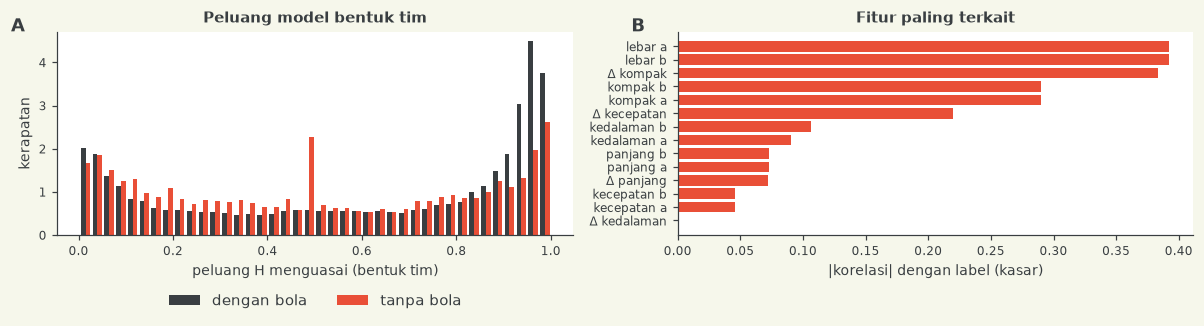

In [5]:
Xall, yall = XY(idx)
MODEL = make_model().fit(Xall, yall)
P_H = 0.5 * (MODEL.predict_proba(F[0])[:, 1] + 1 - MODEL.predict_proba(F[1])[:, 1])
ok_shape = np.isfinite(F[0]).any(1) & np.isfinite(F[1]).any(1)
P_H = np.where(ok_shape, P_H, 0.5)

nb = GRADED & ~OBS_S3
print(f"frame dinilai tanpa bukti bola: {nb.sum()} ({nb.sum() / GRADED.sum():.1%}) | rata-rata |p-0,5| bentuk tim: tanpa bola {np.abs(P_H[nb] - .5).mean():.3f}, dengan bola {np.abs(P_H[GRADED & OBS_S3] - .5).mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist([P_H[GRADED & OBS_S3], P_H[nb]], bins=40, color=[C2, C1], label=["dengan bola", "tanpa bola"], density=True)
ax[0].set(xlabel="peluang H menguasai (bentuk tim)", ylabel="kerapatan", title="Peluang model bentuk tim")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
imp = pd.Series(np.abs(np.corrcoef(np.nan_to_num(Xall).T, yall)[-1, :-1]), index=FEATS).sort_values()
ax[1].barh(imp.index, imp.values, color=C1); ax[1].set(xlabel="|korelasi| dengan label (kasar)", title="Fitur paling terkait")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

## [5] Decoder: bukti bola + bukti bentuk tim

Bukti bola sama dengan 006 (jarak terdekat, τ = 3 m). Bukti bentuk tim memberi $\kappa \cdot \log p_{H}$ untuk `H` dan $\kappa \cdot \log (1 - p_H)$ untuk `A` pada **setiap** frame (juga saat bola ada). λ dikalibrasi ulang per varian ke target eksternal.

In [6]:
G = common.gap_dead_ball(); DEAD = G[G.p_dead >= 0.5]
dist = common.team_distances(); dH, dA = dist[:, 0], dist[:, 1]
OBS_N = np.isfinite(dH) & np.isfinite(dA)
E_N = np.zeros(N); E_N[OBS_N] = np.clip((dA[OBS_N] - dH[OBS_N]) / 3.0, -10, 10)
LPB_H, LPB_A = -np.logaddexp(0, -E_N), -np.logaddexp(0, E_N); LPB_H[~OBS_N] = 0; LPB_A[~OBS_N] = 0
pc = np.clip(P_H, 1e-3, 1 - 1e-3)
LPS_H, LPS_A = np.log(pc), np.log(1 - pc)

def lp(kb, ks):
    return kb * LPB_H + ks * LPS_H, kb * LPB_A + ks * LPS_A

def finish(paths):
    lab = np.full(N, "X", dtype="<U1")
    for (half, a, b), p in zip(BLOCKS3, paths):
        lab[a:b + 1] = np.where(p == 0, "H", "A")
        if half == 2: lab[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows(): lab[int(r.f0):int(r.f1)] = "D"
    return lab

def decode(kb, ks, lam):
    h, a = lp(kb, ks)
    return finish([common.viterbi_2state(h[x:y + 1], a[x:y + 1], lam) for x, y in BL])

def count(lab):
    n, gaps = 0, []
    for _, a, b in BLOCKS3:
        seg = lab[a:b + 1]; st = []
        for t in ("H", "A"):
            s, e = common.runs(seg == t); st += list(s)
        st = np.sort(st); n += len(st)
        if len(st) > 1: gaps += list(np.diff(st) / FPS)
    return n, np.array(gaps)

RATE, RATE_SD, _ = common.external_possession_rate()
TARGET, TARGET_SD = RATE * GRADED_MIN, RATE_SD * GRADED_MIN
print(f"target: {TARGET:.0f} +/- {TARGET_SD:.0f} possession")

SPEC = {"ball": (1.0, 0.0), "shape": (0.0, 1.0), "ball+shape_k02": (1.0, 0.02), "ball+shape_k05": (1.0, 0.05)}
LAMS = [5, 10, 20, 30, 50, 80, 120, 200, 400]
SWEEP = {}
for name, (kb, ks) in SPEC.items():
    SWEEP[name] = [(lam, count(decode(kb, ks, lam))[0]) for lam in LAMS]
display(pd.DataFrame({k: [n for _, n in v] for k, v in SWEEP.items()}, index=[f"λ={l}" for l in LAMS]).T)

target: 208 +/- 21 possession


,λ=5,λ=10,λ=20,λ=30,λ=50,λ=80,λ=120,λ=200,λ=400
ball,696,477,305,247,191,146,134,108,67
shape,350,300,234,206,180,168,158,137,107
ball+shape_k02,684,470,303,243,189,148,132,110,68
ball+shape_k05,669,471,309,243,188,150,131,110,75


Setiap baris menunjukkan jumlah possession prediksi untuk satu kombinasi bukti. Bukti bentuk tim menambah informasi di frame tanpa bola, sehingga jumlah possession pada λ yang sama berubah; kalibrasi ke target eksternal menyamakan skala agar varian dapat dibandingkan.

,λ*
ball,42.8
shape,29.2
ball+shape_k02,41.8
ball+shape_k05,41.5


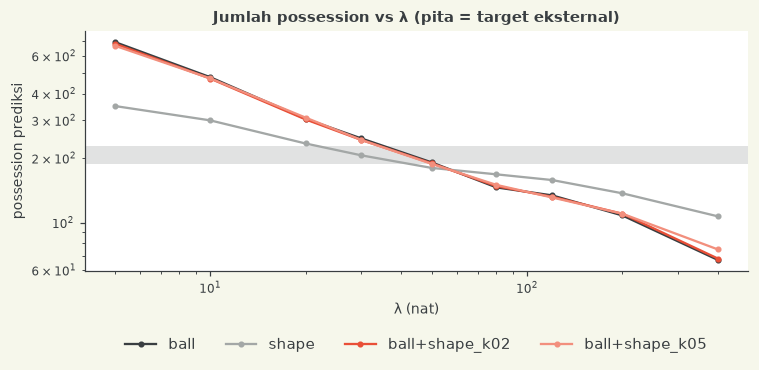

In [7]:
def solve(sweep, target):
    x = np.log([l for l, _ in sweep]); y = np.array([n for _, n in sweep], float)
    if target >= y[0]: return float(np.exp(x[0]))
    if target <= y[-1]: return float(np.exp(x[-1]))
    return float(np.exp(np.interp(-target, -y, x)))

CAL = {k: solve(v, TARGET) for k, v in SWEEP.items()}
display(pd.DataFrame({"λ*": CAL}).round(1))

fig, ax = plt.subplots(figsize=(7, 3.6))
for (k, v), col in zip(SWEEP.items(), (C2, GREY, C1, "#f28f7d")):
    ax.plot([l for l, _ in v], [n for _, n in v], marker="o", ms=3, color=col, label=k)
ax.axhspan(TARGET - TARGET_SD, TARGET + TARGET_SD, color=C2, alpha=0.15, lw=0)
ax.set(xscale="log", yscale="log", xlabel="λ (nat)", ylabel="possession prediksi", title="Jumlah possession vs λ (pita = target eksternal)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4); fig.tight_layout(); plt.show()

## [6] Varian yang dibangun

Setiap varian memakai λ* hasil kalibrasi. Selain jumlah dan durasi possession, dihitung seberapa sering label saat **bola hilang** berbeda dari varian hanya-bola: itulah frame tempat bukti bentuk tim bisa mengubah hasil.

In [8]:
VARS = {"v1_ball": ("ball", SPEC["ball"]), "v2_shape_only": ("shape", SPEC["shape"]),
        "v3_ball_shape_k02": ("ball+shape_k02", SPEC["ball+shape_k02"]), "v4_ball_shape_k05": ("ball+shape_k05", SPEC["ball+shape_k05"])}
for old in OUT.glob("*.csv"): old.unlink()
LAB, rows = {}, []
for name, (key, (kb, ks)) in VARS.items():
    lab = decode(kb, ks, CAL[key]); LAB[name] = lab; write_submission(str(OUT / f"{name}.csv"), lab)
for name, lab in LAB.items():
    n, g = count(lab)
    live = GRADED & ~OBS_N & (lab != "D") & (LAB["v1_ball"] != "D")
    rows.append({"varian": name, "λ*": round(CAL[VARS[name][0]], 1), "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
                 "% D": round(100 * np.mean(lab[GRADED] == "D"), 1),
                 "beda dgn v1 saat bola hilang": f"{np.mean(lab[live] != LAB['v1_ball'][live]):.1%}"})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, g = count(base)
rows.append({"varian": "baseline_smooth50", "λ*": None, "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
             "% D": round(100 * np.mean(base[GRADED] == "D"), 1), "beda dgn v1 saat bola hilang": None})
display(pd.DataFrame(rows))

,varian,λ*,possession,median awal-ke-awal (dtk),% D,beda dgn v1 saat bola hilang
0,v1_ball,42.8,212,20.6,22.7,0.0%
1,v2_shape_only,29.2,210,22.4,22.7,33.2%
2,v3_ball_shape_k02,41.8,210,20.9,22.7,10.3%
3,v4_ball_shape_k05,41.5,204,20.8,22.7,20.7%
4,baseline_smooth50,NaN,594,5.7,32.3,NaN


## [7] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil adalah noise dan tidak dipakai untuk memilih varian.

In [9]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


v1_ball.csv -> VALID


v2_shape_only.csv -> VALID


v3_ball_shape_k02.csv -> VALID


v4_ball_shape_k05.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v3_ball_shape_k02,0.6647,0.5000,11,25.9418
1,2,v1_ball,0.6644,0.5000,11,25.9418
2,3,v4_ball_shape_k05,0.6670,0.4154,9,31.7067
3,4,baseline_smooth50,0.6207,0.3256,26,10.8031
4,5,v2_shape_only,0.6444,0.3143,11,25.9418


# Ringkasan 007

**Yang dikerjakan.** Ditambahkan sumber bukti tim yang tidak memakai bola: classifier gradient boosting atas 14 fitur bentuk tim (kedalaman, panjang, lebar, kekompakan, kecepatan, dan selisihnya, dinormalkan terhadap arah serang per tim dan babak, dengan augmentasi simetris H/A). Label latihnya pseudo-label algoritmik dari bola: frame dengan kendali jelas (|c| > 0,6, 20,3% frame dinilai). Peluang tim hasil model menjadi bukti tambahan Viterbi pada semua frame, dengan bobot κ = 0,02 atau 0,05 (dan satu varian hanya bentuk tim), dan λ dikalibrasi ulang ke target eksternal 006 (208 ± 21 possession) untuk tiap varian. Semua lima berkas lolos `validate_submission.py`. Tidak ada label tangan, tidak ada GT untuk pelatihan, tidak ada data keluar dari mesin.

**Hasil.**
1. **Arah serang terbaca masuk akal:** H menyerang ke kanan di babak 1 dan ke kiri di babak 2, A sebaliknya.
2. **Bentuk tim membawa informasi kepemilikan.** Validasi antar babak terhadap pseudo-label: AUC 0,81 (latih babak 1, uji babak 2) dan 0,87 (sebaliknya), akurasi 74% dan 82%. Itu jauh di atas kebetulan, padahal model tidak melihat bola sama sekali.
3. **Hanya-bentuk-tim bisa mendecode seluruh pertandingan.** `v2_shape_only` menghasilkan 210 possession dengan median awal-ke-awal 22,4 detik, hampir sama dengan varian hanya-bola (212 dan 20,6 detik) dan dengan acuan eksternal (22,3 detik). Pada GT publik macroF1-nya 0,644 dibanding 0,664 untuk hanya-bola, tanpa informasi bola untuk tim.
4. **Bukti bentuk tim mengubah label pada frame tanpa bola:** 10,3% frame tanpa bola berbeda dari hanya-bola untuk κ = 0,02 dan 20,7% untuk κ = 0,05; hanya-bentuk-tim berbeda pada 33,2%.

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v3_ball_shape_k02` 0,665 macroF1 dan 0,500 spellF1, sama dengan `v1_ball` (0,664 dan 0,500); `v4_ball_shape_k05` 0,667 dan 0,415; `v2_shape_only` 0,644 dan 0,314; `baseline_smooth50` 0,621 dan 0,326. Tidak ada keunggulan yang bisa dibedakan dari noise 17 possession, jadi **tidak ada klaim bahwa bukti bentuk tim memperbaiki hasil**.

**Keterbatasan penting.**
- **Pergeseran distribusi.** Model dilatih dan divalidasi pada frame dengan kendali bola jelas, yaitu frame yang relatif mudah. Frame tanpa bola (kotak penalti ramai, duel udara) mungkin lebih sulit, sehingga AUC 0,81 sampai 0,87 kemungkinan terlalu optimistis untuk frame yang justru kita sasar. Tidak ada cara memeriksanya tanpa ground truth.
- **Validasi melingkar sebagian.** Label berasal dari bola, sehingga AUC mengukur kesesuaian dengan bukti bola, bukan kebenaran.
- **κ adalah prior** (1/50), bukan hasil penyetelan.
- Ketepatan batas pergantian belum diukur selain pada GT publik (2 dari 20 transisi cocok sebelumnya).

**Langkah berikutnya.** (a) Ukur ketepatan waktu pergantian secara internal, misalnya konsistensi pergantian antar bukti bola dan bentuk tim di sekitar gap; (b) latih model dengan contoh yang lebih sulit (bukan hanya |c| > 0,6) bila ada cara pseudo-label yang tidak bias; (c) bukti video lokal.